# 02 – Data cleaning log and exploratory data analysis
**QM640 Data Analytics Capstone – Binesh Balakrishnan**

Dependent variable for all research questions: **SLA breach** (1 = breached, 0 = met).
Input: `data/raw/incident_event_log.csv` (event level) and `data/processed/incidents.csv` (one row per incident, created by notebook 01).
Outputs: figures in `figures/`, numbers in `results/eda.json` (used in the interim report).

In [1]:
import os, subprocess
repo = '/content/QM640_data_analytics_capstone'
if not os.path.exists(repo):
    subprocess.run(['git', 'clone', '-q',
                    'https://github.com/binesh29/QM640_data_analytics_capstone.git', repo], check=True)
os.chdir(os.path.join(repo, 'notebooks'))
os.makedirs('../figures', exist_ok=True); os.makedirs('../results', exist_ok=True)

In [2]:
os.makedirs('../src', exist_ok=True)
with open('../src/plot_style.py', 'w') as f:
    f.write('''import matplotlib as mpl
BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
def apply():
    mpl.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.edgecolor': INK2,
        'axes.labelcolor': INK, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
        'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
        'grid.linewidth': 0.8, 'axes.axisbelow': True, 'xtick.color': INK2, 'ytick.color': INK2,
        'legend.frameon': False, 'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight', 'lines.linewidth': 2})
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / d
    h = z * ((p * (1 - p) / n + z**2 / (4 * n**2)) ** 0.5) / d
    return c - h, c + h
''')
print(os.listdir('../src'))

['sample_size.py', 'plot_style.py']


In [3]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, '../src')
import plot_style as ps
ps.apply()
FIG = Path('../figures'); FIG.mkdir(exist_ok=True)
RES = Path('../results'); RES.mkdir(exist_ok=True)
R = {}

## 1. Data cleaning checks (event level)

In [4]:
ev = pd.read_csv('../data/raw/incident_event_log.csv', na_values='?', keep_default_na=False, low_memory=False)
R['events'], R['columns'] = ev.shape
R['exact_duplicate_rows'] = int(ev.duplicated().sum())
R['duplicate_number_modcount'] = int(ev.duplicated(['number', 'sys_mod_count']).sum())
R['state_minus100_rows'] = int((ev['incident_state'] == '-100').sum())
miss = (ev.isna().mean() * 100).round(1).sort_values(ascending=False)
R['event_missing_pct'] = miss[miss > 0].to_dict()
print(R['events'], R['columns'], 'exact duplicates:', R['exact_duplicate_rows'],
      '| duplicate (number, sys_mod_count):', R['duplicate_number_modcount'], '| state -100 rows:', R['state_minus100_rows'])
miss[miss > 0]

141712 36 exact duplicates: 0 | duplicate (number, sys_mod_count): 5 | state -100 rows: 5


,0
caused_by,100.0
vendor,99.8
cmdb_ci,99.7
rfc,99.3
problem_id,98.4
sys_created_by,37.5
sys_created_at,37.5
u_symptom,23.3
assigned_to,19.4
assignment_group,10.0


## 2. Incident-level completeness and outliers

In [5]:
inc = pd.read_csv('../data/processed/incidents.csv', parse_dates=['opened_at', 'resolved_at', 'closed_at'])
R['incidents'] = len(inc)
R['duplicate_incidents'] = int(inc['number'].duplicated().sum())
logcols = [c for c in inc.columns if c.startswith('log_')]
imiss = (inc[['priority', 'category', 'subcategory', 'reassignment_count', 'knowledge', 'sla_breach', 'resolved_at'] + logcols]
         .isna().mean() * 100).round(2)
R['incident_missing_pct'] = imiss[imiss > 0].to_dict()
print('duplicate incident numbers:', R['duplicate_incidents'])
imiss[imiss > 0]

duplicate incident numbers: 0


,0
category,0.03
subcategory,0.03
resolved_at,6.24
log_category,0.16
log_subcategory,0.28
log_u_symptom,23.02
log_location,0.21
log_assignment_group,3.64
log_caller_id,0.01
log_cmdb_ci,99.80


In [6]:
num = inc[['reassignment_count', 'reopen_count', 'sys_mod_count', 'resolution_hours']]
desc = num.describe(percentiles=[.25, .5, .75, .95, .99]).T.round(2)
def iqr_out(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); hi = q3 + 1.5 * (q3 - q1)
    return int((s > hi).sum()), round(float(hi), 2)
out = {c: iqr_out(num[c]) for c in num}
desc['iqr_upper_fence'] = [out[c][1] for c in num]
desc['n_above_fence'] = [out[c][0] for c in num]
R['numeric_summary'] = desc.reset_index().to_dict('records')
R['resolution_missing'] = int(inc['resolution_hours'].isna().sum())
R['resolution_nonpositive'] = int((inc['resolution_hours'] <= 0).sum())
R['resolution_over_1000h'] = int((inc['resolution_hours'] > 1000).sum())
R['opened_range'] = [str(inc['opened_at'].min()), str(inc['opened_at'].max())]
desc

,count,mean,std,min,25%,50%,75%,95%,99%,max,iqr_upper_fence,n_above_fence
reassignment_count,24918.0,0.94,1.57,0.0,0.00,0.0,1.00,4.00,7.0,27.00,2.50,2848
reopen_count,24918.0,0.01,0.15,0.0,0.00,0.0,0.00,0.00,1.0,8.00,0.00,275
sys_mod_count,24918.0,6.68,8.55,1.0,2.00,4.0,8.00,19.00,46.0,129.00,17.00,1470
resolution_hours,23362.0,178.17,532.79,0.0,0.42,22.1,148.48,710.52,2843.4,8070.17,370.57,2383


## 3. Outcome profile

In [7]:
R['breaches'] = int(inc['sla_breach'].sum()); R['breach_rate'] = round(inc['sla_breach'].mean(), 4)
pr = inc.groupby('priority')['sla_breach'].agg(['size', 'sum', 'mean'])
R['priority_profile'] = pr.reset_index().to_dict('records')
print(R['breaches'], R['breach_rate']); pr

9115 0.3658


,size,sum,mean
priority,,,
1 - Critical,270,265,0.981481
2 - High,408,406,0.995098
3 - Moderate,23466,8321,0.354598
4 - Low,774,123,0.158915


### Figure: breach rate by priority (RQ1)

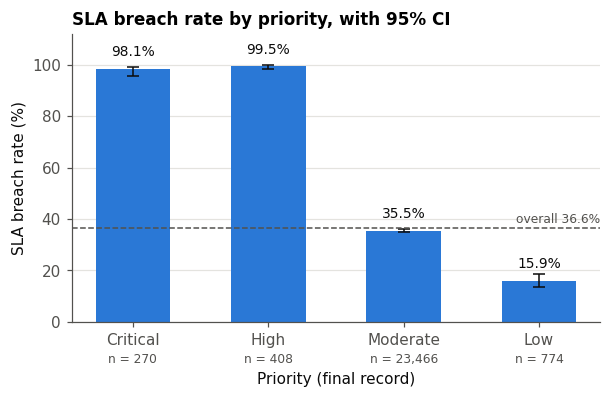

In [8]:
lab = {'1 - Critical': 'Critical', '2 - High': 'High', '3 - Moderate': 'Moderate', '4 - Low': 'Low'}
fig, ax = plt.subplots(figsize=(6.2, 3.4))
x = np.arange(len(pr)); rates = pr['mean'].values * 100
ci = np.array([ps.wilson(k, n) for k, n in zip(pr['sum'], pr['size'])]) * 100
ax.bar(x, rates, width=0.55, color=ps.BLUE)
ax.errorbar(x, rates, yerr=[rates - ci[:, 0], ci[:, 1] - rates], fmt='none', ecolor=ps.INK, capsize=4, lw=1)
for i, (r, n) in enumerate(zip(rates, pr['size'])):
    ax.text(i, min(r + 4, 103), f'{r:.1f}%', ha='center', va='bottom', fontsize=9, color=ps.INK)
    ax.text(i, -12, f'n = {n:,}', ha='center', va='top', fontsize=8, color=ps.INK2)
ax.axhline(inc['sla_breach'].mean() * 100, color=ps.INK2, ls='--', lw=1)
ax.text(3.45, inc['sla_breach'].mean() * 100 + 2, 'overall 36.6%', ha='right', fontsize=8, color=ps.INK2)
ax.set_xticks(x, [lab[p] for p in pr.index]); ax.set_ylim(0, 112); ax.set_ylabel('SLA breach rate (%)')
ax.set_xlabel('Priority (final record)', labelpad=16)
ax.set_title('SLA breach rate by priority, with 95% CI'); ax.grid(axis='x', visible=False)
fig.savefig(FIG / 'fig_breach_by_priority.png'); plt.show()

### Figure: breach rate by number of reassignments (RQ2)

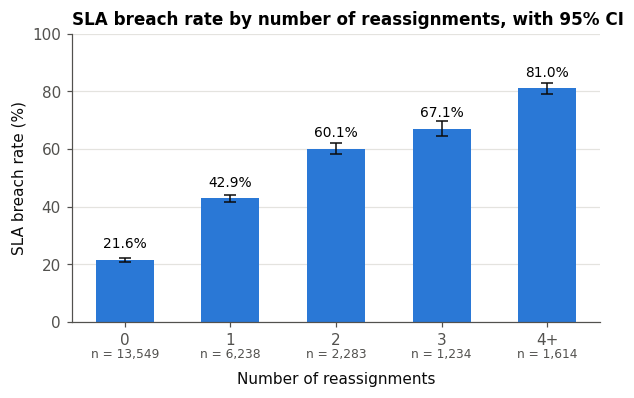

,size,sum,mean
reassign_grp,,,
0,13549,2928,0.216105
1,6238,2678,0.429304
2,2283,1373,0.601402
3,1234,828,0.670989
4+,1614,1308,0.810409


In [9]:
inc['reassign_grp'] = pd.cut(inc['reassignment_count'], [-1, 0, 1, 2, 3, 100], labels=['0', '1', '2', '3', '4+'])
rg = inc.groupby('reassign_grp', observed=True)['sla_breach'].agg(['size', 'sum', 'mean'])
R['reassign_profile'] = rg.reset_index().astype({'reassign_grp': str}).to_dict('records')
fig, ax = plt.subplots(figsize=(6.2, 3.4))
x = np.arange(len(rg)); rates = rg['mean'].values * 100
ci = np.array([ps.wilson(k, n) for k, n in zip(rg['sum'], rg['size'])]) * 100
ax.bar(x, rates, width=0.55, color=ps.BLUE)
ax.errorbar(x, rates, yerr=[rates - ci[:, 0], ci[:, 1] - rates], fmt='none', ecolor=ps.INK, capsize=4, lw=1)
for i, (r, n) in enumerate(zip(rates, rg['size'])):
    ax.text(i, r + 3, f'{r:.1f}%', ha='center', va='bottom', fontsize=9)
    ax.text(i, -9, f'n = {n:,}', ha='center', va='top', fontsize=8, color=ps.INK2)
ax.set_xticks(x, rg.index.astype(str)); ax.set_ylim(0, 100); ax.set_ylabel('SLA breach rate (%)')
ax.set_xlabel('Number of reassignments', labelpad=16)
ax.set_title('SLA breach rate by number of reassignments, with 95% CI'); ax.grid(axis='x', visible=False)
fig.savefig(FIG / 'fig_breach_by_reassignment.png'); plt.show(); rg

### Figure: breach rate by knowledge use within each priority (RQ3)

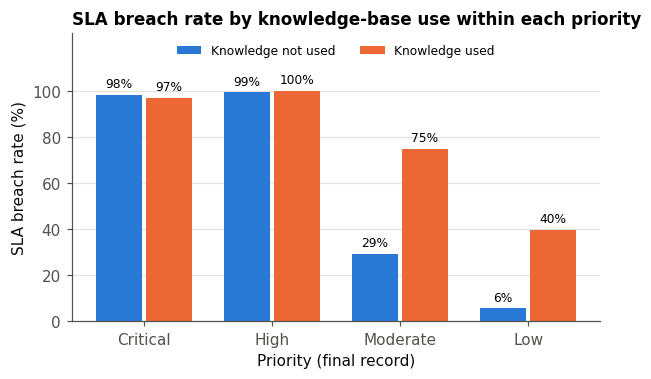

,priority,knowledge,size,mean
0,1 - Critical,False,237,0.983122
1,1 - Critical,True,33,0.969697
2,2 - High,False,329,0.993921
3,2 - High,True,79,1.000000
4,3 - Moderate,False,20261,0.292384
5,3 - Moderate,True,3205,0.747894
6,4 - Low,False,540,0.055556
7,4 - Low,True,234,0.397436


In [10]:
kp = inc.groupby(['priority', 'knowledge'])['sla_breach'].agg(['size', 'mean']).reset_index()
R['knowledge_by_priority'] = kp.to_dict('records')
fig, ax = plt.subplots(figsize=(6.2, 3.4))
x = np.arange(4); w = 0.36
for j, (k, col, name) in enumerate([(False, ps.BLUE, 'Knowledge not used'), (True, ps.ORANGE, 'Knowledge used')]):
    s = kp[kp['knowledge'] == k].set_index('priority').reindex(pr.index)
    xs = x + (j - 0.5) * (w + 0.03)
    ax.bar(xs, s['mean'] * 100, width=w, color=col, label=name)
    for xi, r in zip(xs, s['mean'] * 100):
        ax.text(xi, r + 2, f'{r:.0f}%', ha='center', va='bottom', fontsize=8)
ax.set_xticks(x, [lab[p] for p in pr.index]); ax.set_ylim(0, 125); ax.set_yticks(range(0, 101, 20)); ax.set_ylabel('SLA breach rate (%)')
ax.set_xlabel('Priority (final record)'); ax.legend(loc='upper center', ncol=2, fontsize=8)
ax.set_title('SLA breach rate by knowledge-base use within each priority'); ax.grid(axis='x', visible=False)
fig.savefig(FIG / 'fig_breach_by_knowledge_priority.png'); plt.show(); kp

### Figure: weekly volume and breach rate over time (temporal split for RQ4)

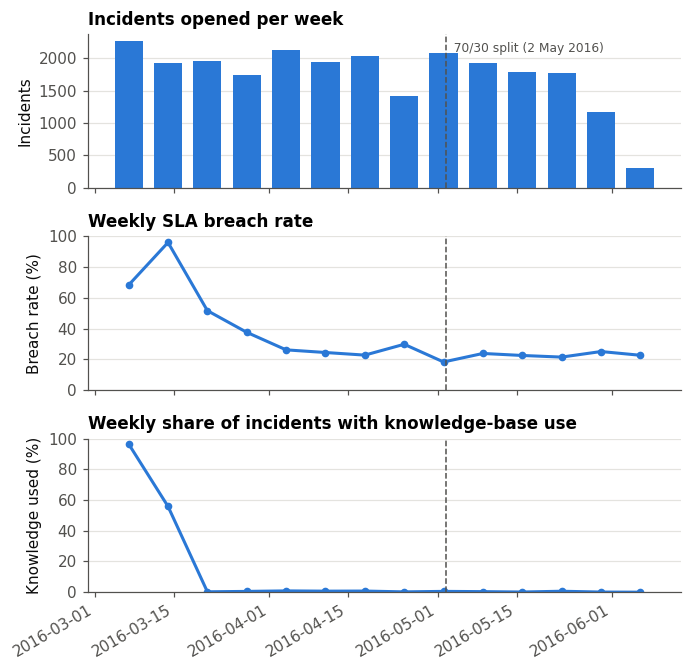

In [11]:
cut = inc.sort_values('opened_at')['opened_at'].iloc[int(len(inc) * 0.7)]
R['temporal_cut'] = str(cut)
wk = inc.set_index('opened_at').resample('W-MON').agg({'sla_breach': ['size', 'mean'], 'knowledge': 'mean'})
wk.columns = ['size', 'mean', 'knowledge']
wk = wk[wk['size'] >= 300]   # weeks with fewer than 300 incidents (first and last partial weeks) are not plotted
fig, (a1, a2, a3) = plt.subplots(3, 1, figsize=(6.4, 6.2), sharex=True)
a1.bar(wk.index, wk['size'], width=5, color=ps.BLUE); a1.set_ylabel('Incidents'); a1.set_title('Incidents opened per week')
a2.plot(wk.index, wk['mean'] * 100, color=ps.BLUE, marker='o', ms=4); a2.set_ylim(0, 100)
a2.set_ylabel('Breach rate (%)'); a2.set_title('Weekly SLA breach rate')
a3.plot(wk.index, wk['knowledge'] * 100, color=ps.BLUE, marker='o', ms=4); a3.set_ylim(0, 100)
a3.set_ylabel('Knowledge used (%)'); a3.set_title('Weekly share of incidents with knowledge-base use')
for a in (a1, a2, a3):
    a.axvline(cut, color=ps.INK2, ls='--', lw=1); a.grid(axis='x', visible=False)
a1.text(cut, a1.get_ylim()[1] * 0.95, '  70/30 split (2 May 2016)', fontsize=8, color=ps.INK2, va='top')
fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(FIG / 'fig_weekly_volume_breach.png'); plt.show()
R['weekly'] = {str(k.date()): [int(v['size']), round(float(v['mean']), 3), round(float(v['knowledge']), 3)] for k, v in wk.iterrows()}

### Figure: resolution time distribution by outcome (descriptive only)

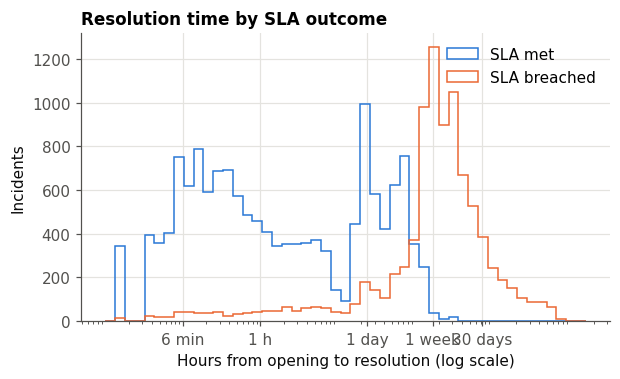

In [12]:
rh = inc[inc['resolution_hours'] > 0]
bins = np.logspace(-2, 4.2, 50)
fig, ax = plt.subplots(figsize=(6.2, 3.4))
for b, col, name in [(0, ps.BLUE, 'SLA met'), (1, ps.ORANGE, 'SLA breached')]:
    ax.hist(rh.loc[rh['sla_breach'] == b, 'resolution_hours'], bins=bins, histtype='step', lw=2, color=col, label=name)
ax.set_xscale('log'); ax.set_xlabel('Hours from opening to resolution (log scale)'); ax.set_ylabel('Incidents')
ax.set_xticks([0.1, 1, 24, 168, 720], ['6 min', '1 h', '1 day', '1 week', '30 days'])
ax.legend(); ax.set_title('Resolution time by SLA outcome')
fig.savefig(FIG / 'fig_resolution_hours.png'); plt.show()
R['resolution_median_by_outcome'] = rh.groupby('sla_breach')['resolution_hours'].median().round(1).to_dict()

### Figure: breach rate by hour of logging (RQ4 feature)

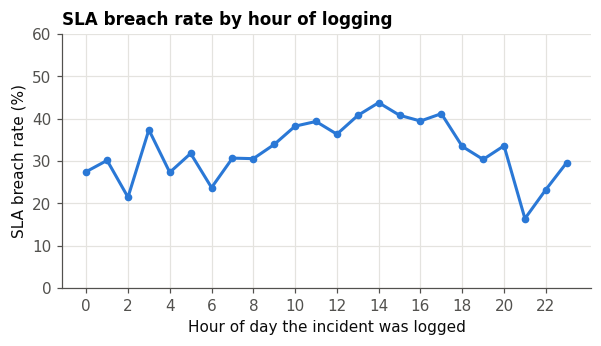

In [13]:
hr = inc.groupby('log_hour')['sla_breach'].agg(['size', 'mean'])
fig, ax = plt.subplots(figsize=(6.2, 3.0))
ax.plot(hr.index, hr['mean'] * 100, color=ps.BLUE, marker='o', ms=4)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('Hour of day the incident was logged'); ax.set_ylabel('SLA breach rate (%)')
ax.set_ylim(0, 60); ax.set_title('SLA breach rate by hour of logging')
fig.savefig(FIG / 'fig_breach_by_hour.png'); plt.show()
R['hour_profile'] = {int(k): [int(v['size']), round(float(v['mean']), 3)] for k, v in hr.iterrows()}
dw = inc.groupby(inc['log_dayofweek'] >= 5)['sla_breach'].agg(['size', 'mean'])
R['weekend_profile'] = {('weekend' if k else 'weekday'): [int(v['size']), round(float(v['mean']), 3)] for k, v in dw.iterrows()}

## 4. Category concentration

In [14]:
cat = inc.groupby('category')['sla_breach'].agg(['size', 'mean']).sort_values('size', ascending=False)
R['n_categories'] = int(len(cat)); R['top10_category_share'] = round(float(cat['size'].head(10).sum() / len(inc)), 3)
R['categories_lt30'] = int((cat['size'] < 30).sum())
R['top_categories'] = cat.head(8).reset_index().to_dict('records')
cat.head(10)

,size,mean
category,,
Category 42,3558,0.193648
Category 26,3338,0.304673
Category 53,2678,0.376774
Category 46,2432,0.515625
Category 32,1522,0.247700
Category 9,1155,0.407792
Category 37,1144,0.336538
Category 23,1063,0.475071
Category 20,1047,0.230181


In [15]:
json.dump(R, open(RES / 'eda.json', 'w'), indent=1, default=str); print('saved')

saved
